# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Andini Putri Ahmawati
- **Email:** ds014b6x0190@student.devacademy.id
- **ID Dicoding:** DS014B6X0190

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata dan total penyewaan sepeda harian (`cnt`) pada berbagai kondisi cuaca (`weathersit`) dan musim (`season`) selama periode tahun 2011 hingga 2012, dan juga kondisi manakah yang menyebabkan penurunan penyewaan yang paling drastis?
  - *Specific:* Berfokus pada pengaruh variabel kondisi cuaca (`weathersit`) dan musim (`season`) terhadap jumlah penyewaan sepeda (`cnt`).
  - *Measurable:* Diukur secara kuantitatif menggunakan metrik rata-rata (*mean*) dan total (*sum*) jumlah dari penyewaan sepeda harian.
  - *Action-Oriented:* Acuan bagi manajemen operasional untuk mengatur alokasi armada sepeda, jadwal perawatan, dan strategi promosi dinamis didasarkan cuaca/musim.
  - *Relevant:* Armada yang tersedia dan tepat sesuai kondisi lingkungan sangat krusial untuk memaksimalkan pendapatan dan efisiensi operasional.
  - *Time-bound:* Dibatasi secara jelas pada periode tahun 2011 hingga 2012.
- **Pertanyaan 2:** Pada jam berapakah (`hr`) rata-rata penyewaan sepeda mencapai titik tertinggi dan terendah ketika hari kerja (`workingday == 1`) dibandingkan dengan hari libur/akhir pekan (`workingday == 0`)?
  - *Specific:* Membandingkan pola jam sibuk (*peak hours*) penyewaan sepeda antara hari kerja dan hari libur.
  - *Measurable:* Diukur menggunakan rata-rata jumlah penyewaan sepeda per jam (`hr`).
  - *Action-Oriented:* Menjadi dasar penjadwalan distribusi ulang (*rebalancing*) stok sepeda di stasiun-stasiun utama sebelum jam sibuk dimulai.
  - *Relevant:* Mencegah kekosongan unit sepeda di stasiun saat permintaan memuncak.
  - *Time-bound:* Dibatasi pada rentang data per jam sepanjang periode 2011 hingga 2012.

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
day_df = pd.read_csv("day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
hour_df = pd.read_csv("hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Proses dari *Gathering Data* telah berhasil memuat dua dataset utama: `day_df` (data harian) dan juga `hour_df` (data per jam).
- Kedua dataset tersebut memuat variabel lingkungan dan target yang serupa, namun `hour_df` memiliki resolusi waktu yang lebih spesifik dengan adanya tambahan kolom jam (`hr`).

### Assessing Data

In [5]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [14]:
print("Missing values day_df:\n", day_df.isna().sum())
print("\nJumlah duplikasi day_df: ", day_df.duplicated().sum())
day_df.describe()
print("Jumlah nilai hum == 0 di day_df:", (day_df['hum'] == 0).sum())
print("Jumlah nilai hum == 0 di hour_df:", (hour_df['hum'] == 0).sum())

Missing values day_df:
 instant            0
dteday             0
season             0
yr                 0
mnth               0
holiday            0
weekday            0
workingday         0
weathersit         0
temp               0
atemp              0
hum                0
windspeed          0
casual             0
registered         0
cnt                0
rental_category    0
dtype: int64

Jumlah duplikasi day_df:  0
Jumlah nilai hum == 0 di day_df: 1
Jumlah nilai hum == 0 di hour_df: 22


In [7]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [8]:
print("Missing values hour_df:\n", hour_df.isna().sum())
print("\nJumlah duplikasi hour_df: ", hour_df.duplicated().sum())
hour_df.describe()

Missing values hour_df:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Jumlah duplikasi hour_df:  0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


#### Identifying ... problem

In [ ]:
day_df.info()

**Steps to Take:**
- Mengubah tipe data pada kolom `dteday` dari `object` menjadi `datetime` pada dataset `day_df`.
- Mengubah tipe data pada kolom `dteday` dari `object` menjadi `datetime` pada dataset `hour_df`.

**Insight:** (Opsional)
- Secara keseluruhan dataset sudah sangat bersih karena tidak ditemukan *missing values* (data kosong) maupun duplikasi data yang ada pada kedua dataset.
- Satu-satunya kecacatan data yang perlu diperbaiki di tahap *Cleaning Data* yaitu hanya kesalahan tipe data pada kolom tanggal (`dteday`).

### Cleaning Data

#### Fixing ... problem

In [9]:
# Mengubah tipe data kolom dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Memastikan tipe data sudah berubah
print("Tipe data day_df setelah cleaning:")
day_df.info()

print("\nTipe data hour_df setelah cleaning:")
hour_df.info()

Tipe data day_df setelah cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64      

In [15]:
# 1. Membersihkan nilai kelembapan (hum) yang bernilai 0 dengan menggantinya menggunakan nilai rata-rata (mean)
mean_hum_day = day_df.loc[day_df['hum'] > 0, 'hum'].mean()
day_df['hum'] = day_df['hum'].replace(0, mean_hum_day)

mean_hum_hour = hour_df.loc[hour_df['hum'] > 0, 'hum'].mean()
hour_df['hum'] = hour_df['hum'].replace(0, mean_hum_hour)

# 2. Verifikasi ulang untuk memastikan sudah bersih menjadi 0
print("Setelah dibersihkan - Sisa hum == 0 di day_df:", (day_df['hum'] == 0).sum())
print("Setelah dibersihkan - Sisa hum == 0 di hour_df:", (hour_df['hum'] == 0).sum())

Setelah dibersihkan - Sisa hum == 0 di day_df: 0
Setelah dibersihkan - Sisa hum == 0 di hour_df: 0


**Insight:** (Opsional)
- Telah dilakukan perbaikan tipe data pada kolom `dteday` di dataset `day_df` dan `hour_df`.
- Tipe data berhasil dikonversi yang semula dari `object` menjadi format `datetime` menggunakan fungsi `pd.to_datetime()`. Hal ini akan memastikan keakuratan perhitungan pada tahap visualisasi yang melibatkan waktu (time-series).

## Exploratory Data Analysis (EDA)

### Explore ...

In [10]:
# Eksplorasi data harian: Jumlah penyewaan berdasarkan musim (season)
# Keterangan: 1=Springer, 2=Summer, 3=Fall, 4=Winter
print("Total Penyewaan Sepeda Berdasarkan Musim:")
display(day_df.groupby(by="season").agg({
    "cnt": "sum"
}).sort_values(by="cnt", ascending=False))

print("\n", "="*50, "\n")

# Eksplorasi data per jam: 5 Jam dengan penyewaan tertinggi
print("Top 5 Jam Tersibuk Penyewaan Sepeda:")
display(hour_df.groupby(by="hr").agg({
    "cnt": "sum"
}).sort_values(by="cnt", ascending=False).head())

Total Penyewaan Sepeda Berdasarkan Musim:


,cnt
season,
3,1061129
2,918589
4,841613
1,471348




Top 5 Jam Tersibuk Penyewaan Sepeda:


,cnt
hr,
17,336860
18,309772
8,261001
16,227748
19,226789


**Insight:** (Opsional)
- Berdasarkan dari eksplorasi data harian, musim gugur (*season* 3) mencatat total penyewaan sepeda tertinggi jika dibandingkan musim lainnya.
- Berdasarkan eksplorasi data per jam, waktu tersibuk (*peak hours*) penyewaan sepeda terjadi pada sore hari, yaitu pukul 17:00 dan 18:00, yang memiliki kemungkinan besar bertepatan dengan jam pulang kerja.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_2797/466256457.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


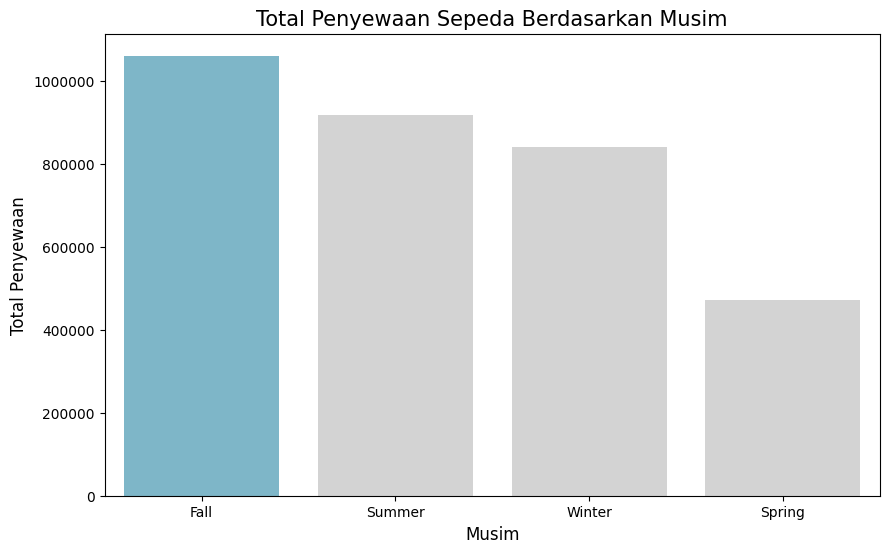

In [11]:
# Menyiapkan data dan nama musim
season_data = day_df.groupby('season')['cnt'].sum().reset_index()
season_data['season_name'] = season_data['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})

# Membuat grafik Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='season_name',
    y='cnt',
    data=season_data.sort_values(by='cnt', ascending=False),
    palette=['#72BCD4', '#D3D3D3', '#D3D3D3', '#D3D3D3']
)

plt.title("Total Penyewaan Sepeda Berdasarkan Musim", loc="center", fontsize=15)
plt.xlabel("Musim", fontsize=12)
plt.ylabel("Total Penyewaan", fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

### Pertanyaan 2:

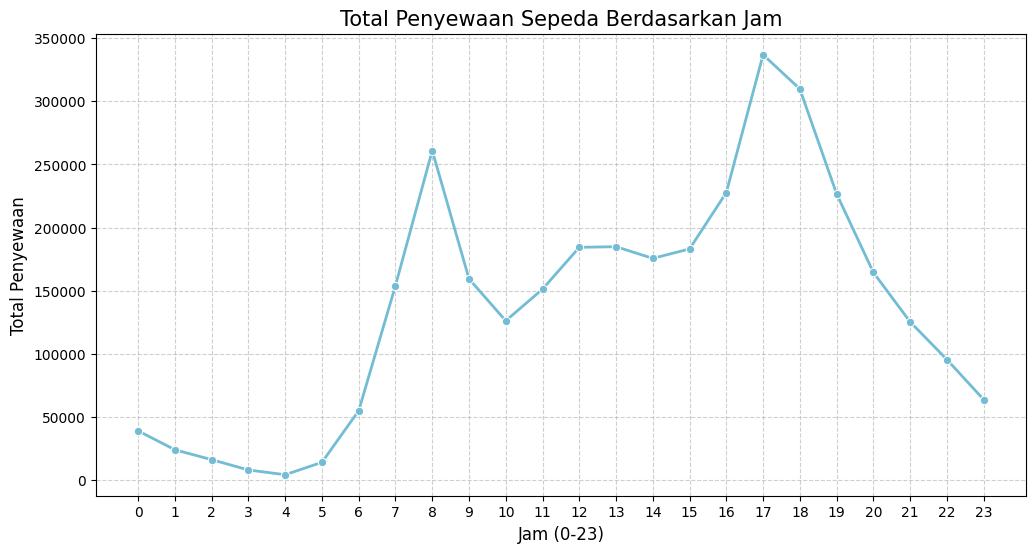

In [12]:
# Menyiapkan data untuk melihat tren per jam
hourly_rentals = hour_df.groupby('hr')['cnt'].sum().reset_index()

# Membuat grafik Line Chart
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='hr',
    y='cnt',
    data=hourly_rentals,
    marker='o',
    linewidth=2,
    color='#72BCD4'
)

plt.title("Total Penyewaan Sepeda Berdasarkan Jam", loc="center", fontsize=15)
plt.xlabel("Jam (0-23)", fontsize=12)
plt.ylabel("Total Penyewaan", fontsize=12)
plt.xticks(range(0, 24)) # Menampilkan jam dari 0-23
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Insight:** (Opsional)
- Tren penyewaan sepeda mencapai puncaknya (peak hour) pada sore hari, yaitu pukul 17:00. Sebaliknya, waktu paling sepi peminjaman terjadi pada dini hari pukul 04:00. Pola ini sejalan dengan jam pulang kerja masyarakat.

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_2797/2316392393.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


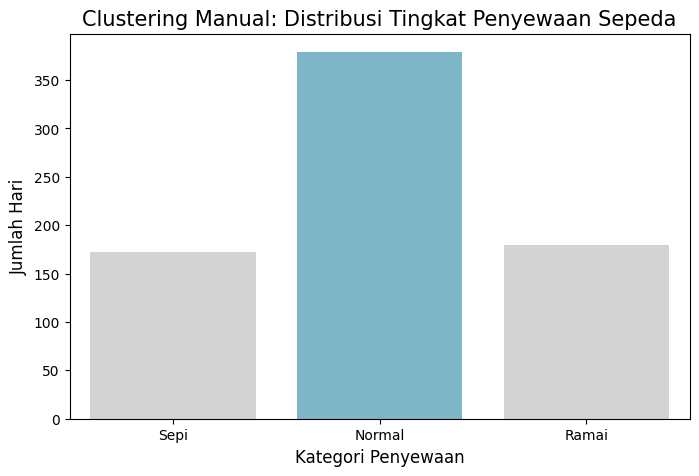

In [13]:
# Analisis Lanjutan: Clustering Manual (Binning) Tingkat Penyewaan Harian
# Pengelompokan hari menjadi 3 kategori: Sepi (<3000), Normal (3000-6000), Ramai (>6000)
day_df['rental_category'] = day_df['cnt'].apply(lambda x: 'Sepi' if x <= 3000 else ('Normal' if x <= 6000 else 'Ramai'))

# Menghitung jumlah hari pada tiap kategori
category_counts = day_df['rental_category'].value_counts().reset_index()
category_counts.columns = ['Kategori', 'Jumlah_Hari']

# visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(
    x='Kategori',
    y='Jumlah_Hari',
    data=category_counts,
    order=['Sepi', 'Normal', 'Ramai'],
    palette=['#D3D3D3', '#72BCD4', '#D3D3D3']
)
plt.title("Clustering Manual: Distribusi Tingkat Penyewaan Sepeda", loc="center", fontsize=15)
plt.xlabel("Kategori Penyewaan", fontsize=12)
plt.ylabel("Jumlah Hari", fontsize=12)
plt.show()

**Insight:** (Opsional)
- Melalui teknik *clustering manual* (binning), distribusi tingkat penyewaan berhasil dikelompokkan menjadi 3 kategori yaitu: Sepi (<= 3000), Normal (3001 - 6000), dan Ramai (> 6000).
- Terlihat juga bahwa mayoritas hari dalam dataset memiliki tingkat penyewaan di kategori **"Normal"**. Ini berguna untuk memetakan frekuensi terjadinya hari-hari sibuk bagi perusahaan, dibandingkan dengan hari-hari sepi sehingga persiapan sepeda bisa lebih optimal.

## Conclusion & Recommendation

In [16]:
import os

# Membuat folder 'dashboard' jika belum ada
os.makedirs("dashboard", exist_ok=True)

# Mengekspor data bersih untuk digunakan oleh dashboard Streamlit
day_df[["dteday", "season", "workingday", "weathersit", "cnt"]].to_csv("dashboard/main_day.csv", index=False)
hour_df[["dteday", "season", "hr", "workingday", "cnt"]].to_csv("dashboard/main_hour.csv", index=False)

print("Berhasil mengekspor main_day.csv dan main_hour.csv ke dalam folder dashboard!")

Berhasil mengekspor main_day.csv dan main_hour.csv ke dalam folder dashboard!


- **Conclusion pertanyaan 1:** Berdasarkan analisis yang sudah dilakukan melalui visualisasi data harian, penyewaan sepeda paling laris terjadi pada Musim Gugur (Fall) dengan total mencapai lebih dari 1 juta penyewaan. Sebaliknya, angka penyewaan paling rendah terjadi pada Musim Semi (Spring).
- **Conclusion pertanyaan 2:** Sedangkan berdasarkan analisis tren per jam, waktu penyewaan sepeda paling sibuk (*peak hour*) terjadi pada pukul 17:00 (sore hari/jam pulang kerja), dan untuk waktu yang paling sepi terlihat berada di pukul 04:00 dini hari.

**Rekomendasi Action Item:**
- **Manajemen Armada Sore Hari:** Perusahaan masih perlu memastikan ketersediaan sepeda dalam jumlah maksimal pada rentang pukul 16:00 hingga 18:00 sore untuk mengakomodasi atau mengatasi tingginya permintaan.
- **Strategi Promosi Musim Semi:** Akan lebih baik jika engadakan kampanye marketing, diskon, atau *event* bersepeda khusus pada Musim Semi (Spring) untuk menarik minat pelanggan dan menaikkan angka penyewaan di musim yang paling sepi tersebut.